# **Pre-lab Questions**

##### 1. What is the main goal of a decision tree algorithm in classification?

As the name suggests, of course, decision trees in classification help accurately classify the classes. This happens with the utilization of the values of attributes to split the dataset further and find the purest classification in accordance with the target variable.
   
##### 2. If a dataset subset contains an equal number of instances from two different classes, what would you expect its Entropy value to be (0, 0.5, or 1)? Why?

A dataset with an equal number of instances from two different classes would have the maximum impurity, thus making its entropy value to be 1.

An equal number of instances would bring equal probabilities to both classes. Using the formula would result to a value of 1, with 50% probability to both classes:

$$
\textit{Formula:}
$$
$$
E(S)=-\sum_{i=1}^{C} p_i \log_2(p_i)
$$

$$
\textit{Getting the Entropy:}
$$
$$
E(S)=-0.5 \log_2(0.5) - 0.5 \log_2(0.5)
$$
$$
E(S)=-0.5(-1) - 0.5(-1)
$$
$$
E(S)=0.5 + 0.5
$$
$$
E(S)=1
$$

   
##### 3. If splitting a dataset by attribute 'A' results in all subsets being perfectly pure, what would be the Information Gain for attribute 'A'?
   
If all the subsets become perfectly pure, then the entropy after partitioning will be 0. This makes the Information Gain maxed out, which makes it 1 (100% pure), as it is perfectly pure.

# **Exploring Entropy and Information Gain**

**Importing Libraries**

In [1]:
#Pandas is a very useful and common library for source data analysis and manipulating data (Pandas, 2018). 
#This activity utilized dataframes that easily manipulates rows, columns, and any data in particular without affecting the original dataset.
import pandas as pd
#This import is numerical python which is for any mathematical functions for coding programs (Numpy, 2024).
#In this activity, it has been used for computing the entropy and weighted entropy according to its corresponding formula.
import numpy as np
#This imports the Decision Tree classified under Scikit Learn for classifying data into categories through tree splits (GeeksforGeeks, 2024).
#This activity used this mainly to build the tree, visualize, and analyze its splits and leaf nodes.
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz, _tree
#The tree module under Scikit Learn deals with classification and regression for creating, training, and visualizing these models (Scikit Learn, 2025).
#This import is used for the tree later to utilize the plot_tree().
from sklearn import tree
#Graphviz is an open source software to represent information through graphs and networks (Graphviz, 2021).
#This has been used for a clearer display of the trees, aside from SK Learn's 'plot_tree()' function.
import graphviz
#IPython is a toolkit mainly for interactive computing that can display better representations of the inputted data .
#This import is for a better display of the tree graphs with titles even inside loops.
from IPython.display import display, Markdown

# Observe Initial Criteria (Root Node Analysis)

In [2]:
#This read the original dataset, 'balloon_dataset.csv' to be stored in the pandas dataframe.
#This dataframe will be used to understand the data and compute entropies.
df = pd.read_csv('balloon_dataset.csv')

In [3]:
#This displays the frequency table of the target variable 'inflated'.
#This gets and counts the value under the target column and stores it in the 'freq_table' variable.
freq_table = df['inflated'].value_counts().reset_index()

In [4]:
#This names the columns for the displayed table later.
#'Value' and 'Frequency' were the column names assigned.
freq_table.columns = ['Value', 'Frequency']

In [5]:
#This displays the frequency table that was set earlier.
#This shows that 9 out of 16 instances are false and 7 out of 16 instances are true for the inflated column in the dataset.
freq_table

,Value,Frequency
0,F,9
1,T,7


In [6]:
#This is the entropy function that calculates the entropy of a given parameter.
#This function follows the entropy formula to get the measure of randomness in a dataset.
def entropy(target_col):
    #This line calculates the probability of each unique value from the given input.
    #This mainly gets the count of the unique value and converts them to propbabilities with the 'normalize=True'.
    probs = target_col.value_counts(normalize=True)
    #This is the formula for getting the entropy measurement.
    #This uses the numpy library for logs and even a summation of this then returns the function.
    return -np.sum(probs * np.log2(probs))

#This function is the conditional entropy function that calculates the weighted average of the target variable after partitioned by an attribute.
#This takes in a dataframe, not limited to the original, the attribute variable, and the target variable to compute.
def conditional_entropy(df, attr, target):
    #This initializes the weighted_entropy to 0.
    #This will accumulate the weighted_entropy of each subset of the grouped dataframe by the given attribute.
    weighted_entropy = 0
    #This gets the total number of items in the dataframe.
    #The total will be used to determine the weight of the object by comparing it to the number of items in the subset.
    total = len(df)

    #This is a loop statement that goes through the unique values of the given attribute.
    #A subset is also created for each unique value of the attribute that only contains the said value in its rows.
    for val, subset in df.groupby(attr):
        #This calculates for the weight of the current subset.
        #It gets the total items from the subset and divides it to the total items in the dataframe.
        weight = len(subset) / total
        #This is the code that calculates for the weighted_entropy that is accumulated.
        #This multiplies the weight to the calculated entropy of its corresponding target column.
        weighted_entropy += weight * entropy(subset[target])

    #This returns the accumulated weighted_entropy.
    #This contains the average value of entropy across the subsets of the attribute, weighted by their size.
    return weighted_entropy

#This is the function to get the value of information gain of an attribute.
#This measures the reduction in entropy of the target variable when split on a certain attribute.
def information_gain(df, attr, target):
    #This gets the entropy of the target column.
    #It is then stored inside 'total_entropy' to be used later.
    total_entropy = entropy(df[target])
    #This gets the weighted entropy of the attribute once again.
    #This is stored inside 'cond_ent' which will be used for the next line.
    cond_ent = conditional_entropy(df, attr, target)
    #This is the formula to get the information gain if the attribute is used for the split.
    #The entropy of the target variable is reduced by the average entropy of the attribute. 
    return total_entropy - cond_ent


In [7]:
#This executes the 'entropy()' function defined earlier to calculate for the entropy.
#The target variable is used as the parameter to compute and then stored in the 'inflated_ent' variable for printing later.
inflated_ent = entropy(df['inflated'])
#This prints the calculated entropy value from the 'entropy()' function earlier.
#This code displays 4 decimal places of the 'inflated_ent' float as per code '.4f'.
print(f"Entropy of Inflated (Target Feature): \n{inflated_ent:.4f}")

Entropy of Inflated (Target Feature): 
0.9887


In [8]:
#This defines an array of all the attributes in the dataset that will be evaluated later.
#These are independent variables in the dataset used for splitting the decision tree.
attrs = ['color', 'size', 'act', 'age']
#This initializes an empty dictionary that will hold the values for the weighted entropy.
#This is for storing their values for each attribute, to be accessed for printing later.
cond_ents = {}
#This initializes an empty dictionary that will hold the values for the information gain.
#This is for storing their values for each attribute, to be accessed for printing later.
info_gain = {}

#This is a loop statement to calculate the weighted entropy and information gain of each attribute.
#All attributes in the 'attrs' list will be accessed for computing based on its data values.
for attr in attrs:
    #This calculates the weighted entropy for each attribute, with inflated as the target variable, and the original dataframe as the passed df.
    #The value is then stored inside the 'cond_ents' dictionary.
    cond_ents[attr] = conditional_entropy(df, attr, 'inflated')
    #This calculates the information gain for each attribute, with inflated as the target variable, and the original dataframe as the passed df.
    #The value is then stored inside the 'info_gain' dictionary.
    info_gain[attr] = information_gain(df, attr, 'inflated')

#This loop statement is for printing the weighted entropy of each attribute.
#This goes through each item of the 'cond_ents' dictionary.
for attr, val in cond_ents.items():
    #This 'capitalize()' function capitalizes the name of the attribute.
    #The 'val: .4f' assigns four (4) decimal places to be displayed from the float, 'val'.
    print(f"Conditional Entropy of {attr.capitalize()}: {val:.4f}")

#This just adds a new line after printing the weighted entropy of each attribute.
#This serves for the purpose of readability.
print('\n')

#This loop statement is for printing the information gain of each attribute.
#This goes through each item of the 'info_gain' dictionary.
for attr, val in info_gain.items():
    #This 'capitalize()' function capitalizes the name of the attribute.
    #The 'val: .4f' assigns four (4) decimal places to be displayed from the float, 'val'.
    print(f"Information Gain of {attr.capitalize()}: {val:.4f}")

Conditional Entropy of Color: 0.8829
Conditional Entropy of Size: 0.8829
Conditional Entropy of Act: 0.8829
Conditional Entropy of Age: 0.7754


Information Gain of Color: 0.1058
Information Gain of Size: 0.1058
Information Gain of Act: 0.1058
Information Gain of Age: 0.2133


### Discussion and Insights
- - -

* The attribute with the highest information gain would be Age (0.2133).
* The entropy of the entire dataset before any splits is basically the **entropy of the target feature (Inflated)**, which is 0.9887.
  >$$
  IG = E_{\text{initial}} - E_{\text{weighted avg}}
  $$
  All the information gain calculations made above (which is the first split) used _'inflated_entropy'_ as the $E_{\text{initial}}$. This confirms that 0.9887 is the original entropy of the dataset, before any attribute-based splits.
  $$
  IG = 0.9887
  $$
  This means that **98.87%** of the uncertainty can be reduced with the right, informative attribute splits.



- - -
**_With this, attribute Age becomes the root node of the Decision Tree._**
- - -

# Trace the Tree Building

In [9]:
#This is a function that would trace the tree building of the Decision Tree for the 'balloon_dataset.csv'.
#This takes in the original dataframe, four attributes of the dataset, the 'inflated' target variable, and a depth of 0 for initizalization.
def build_tree(df, attributes, target, depth=0):
    #This line of code is mainly for readability and visualization for the tracing of the tree building.
    #This creates an indent depending on the current depth of the tree.
    indent = "  " * depth  
    #Now, this is an if-statement that checks if the current node is a leaf node by checking if there is only one unique value under the target column.
    #If all the values of the 'inflated' column are the same, then the node would be considered a leaf node.
    #After checking if the statement is true, it would then print the unique value inside the leaf node and return the function call.
    if len(df[target].unique()) == 1:
        print(f"{indent}Leaf Node: {df[target].iloc[0]}")
        return
    #This is an extra if-statement to check if there are still attributes left to split on.
    #Once this occurs, the node will be considered a leaf node and return to prevent more splits, despite not being in its purest form.
    #mode() retrieves the most frequent element along the selected axis (Pandas, 2024), in this case, [0] is for the columns.
    if not attributes:
        print(f"{indent}Leaf Node (no attributes left): {df[target].mode()[0]}")
        return

    #This line calculates the information gain for the remaining attributes through iteration in the attributes list.
    #After this, the values are stored in the gains dictionary to be accessed for later.
    gains = {attr: information_gain(df, attr, target) for attr in attributes}
    #This line retrieves the highest value of information gain in the dictionary using the max() function.
    #The key, which is the information gain value of the attribute, is used to compare values.
    #It is then stored in the 'best_attr' variable which will be used for later.
    best_attr = max(gains, key=gains.get)
    #This line prints which attribute would be the best to split on based on the information gain.
    #This output would help in tracing the decision-making process of the algorithm.
    print(f"{indent}Split on '{best_attr}' (Info Gain = {gains[best_attr]:.4f})")

    #This for loop statement goes through each unique value of the 'best_attr' and creates a subset dataframe of using the unique value.
    #This would partition the data based on the chosen attribute and their corresponding values.
    for val, subset in df.groupby(best_attr):
        #This is where the indent is used for readability depending on the depth of the split.
        #This line also shows on what unique value is the current path of the tree.
        print(f"{indent}  If {best_attr} == {val}:")
        #Now, this line is a recursive call of the function 'build_tree', but this time, the best attribute is removed from the attributes list.
        #It is also noticeable the depth is now 2 for the future indents (first indent = split on best attribute, second indent = current path).
        build_tree(subset, [a for a in attributes if a != best_attr], target, depth+2)

In [10]:
#This line of code is to execute the 'build_tree' function for tree building tracing.
#It is evident with the output that there are seven (7) leaf nodes after the tree building.
build_tree(df, attrs, 'inflated')

Split on 'age' (Info Gain = 0.2133)
  If age == ADULT:
    Split on 'act' (Info Gain = 0.5577)
      If act == DIP:
        Split on 'color' (Info Gain = 0.3113)
          If color == PURPLE:
            Leaf Node: F
          If color == YELLOW:
            Split on 'size' (Info Gain = 1.0000)
              If size == LARGE:
                Leaf Node: F
              If size == SMALL:
                Leaf Node: T
      If act == STRETCH:
        Leaf Node: T
  If age == CHILD:
    Split on 'color' (Info Gain = 0.1981)
      If color == PURPLE:
        Leaf Node: F
      If color == YELLOW:
        Split on 'size' (Info Gain = 0.9183)
          If size == LARGE:
            Leaf Node: F
          If size == SMALL:
            Leaf Node: T


### Discussion and Insights
- - -

* The algorithm selects a feature to split on through finding the **highest information gain** among the remaining attributes.
    > ```best_attr = max(gains, key=gains.get)```
    >
    > This gets the highest information gain among the others.


    > ```for val, subset in df.groupby(best_attr):```
    >
    > The best attribute is then used in the loop to create a dataframe with a subset of its values.
* A node becomes a leaf when it is pure, wherein **all target values (under inflated) have the same value.**
    ```
    If age == ADULT:
      If act == DIP:
          If color == PURPLE:
            Leaf Node: F
    ```

    > Purple becomes a leaf node as all its values under 'inflated' contains 'F'.

* A node becomes a leaf when **no more features are left to split.**
    > In this tree, no node used up all its features.
    >
    > But the ```build_tree``` function displays an evident output when there are no attributes left and gets its most frequent value among the target column:
    >
    > ```print(f"{indent}Leaf Node (no attributes left): {df[target].mode()[0]}")```

* A node can also become a leaf when the max depth is reached, but this is **not applicable** to the tracing process of the ```build_tree``` function.


# Analyze the Next Splitting Criteria
- - -

#### **Branch 1: age = ADULT**
* Remaining features:
  > * act
  > * color
  > * size

* Information Gain values within this branch:
  > * IG(act) = 0.5577
  > * IG(color) = 0.3113
  > * IG(size) = (used later under color = YELLOW)

* Next split chosen:
  > act (highest IG = 0.5577)

# - - - - - #

#### **Branch 2: age = CHILD**
* Remaining features:
  > * act
  > * color
  > * size

* Information Gain values within this branch:
  > * IG(act) = 0 (not chosen
  > * IG(color) = 0.1981
  > * IG(size) = (used later under color = YELLOW)

* Next split chosen:
  > color (highest IG = 0.1981)
  

**Discussion and Insights**
- - -

* Each branch only uses the unused features to split.
* The criteria for picking will be the one with the highest Information Gain.
* Only the unused features will be compared to determine the next split.
* This will continue to split until either the target values are pure, the no unused features are left, or possibly the maximum depth when specified has been reached.


# View the Tree Visualization
- - -

In [11]:
#This initializes the creation of the decision tree model to the 'clf' variable.
#Inside the parameters, entropy was used to meaure the quality of the split for the information gain (Scikit Learn, 2019). 
clf = DecisionTreeClassifier(criterion="entropy")

#This is line of code creats the attribute matrix containing the input data.
#It only selects the columns specified in the 'attrs' array which holds the following values: color, size, act, age.
X = df[attrs]
#This line uses the function 'get_dummies()' to perform the one-hot encoding on X.
#This is because values under the given attributes have categorical variables, but the tree would be able to utilize numerical data much better.
#Simply, this converts the categorical data with 0s and 1s to make the data fit for the decision tree model later.
X_encoded = pd.get_dummies(X)
#Along with 'X', the 'y' variable is also specified for the target variable.
#As specified in the activity, the target is the inflated column thus the code df['inflated'].
y = df['inflated']


#This line of code trains the decision tree model by learning the most optimal decision with the least entropy as specified in the criterion earlier.
#This takes the numerical data of X which is 'X_encoded' and the target 'y' as the input.
clf.fit(X_encoded, y)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


[Text(0.4444444444444444, 0.9, 'age_ADULT <= 0.5\nentropy = 0.989\nsamples = 16\nvalue = [9, 7]\nclass = F'),
 Text(0.2222222222222222, 0.7, 'size_SMALL <= 0.5\nentropy = 0.592\nsamples = 7\nvalue = [6, 1]\nclass = F'),
 Text(0.3333333333333333, 0.8, 'True  '),
 Text(0.1111111111111111, 0.5, 'entropy = 0.0\nsamples = 4\nvalue = [4, 0]\nclass = F'),
 Text(0.3333333333333333, 0.5, 'color_PURPLE <= 0.5\nentropy = 0.918\nsamples = 3\nvalue = [2, 1]\nclass = F'),
 Text(0.2222222222222222, 0.3, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1]\nclass = T'),
 Text(0.4444444444444444, 0.3, 'entropy = 0.0\nsamples = 2\nvalue = [2, 0]\nclass = F'),
 Text(0.6666666666666666, 0.7, 'act_DIP <= 0.5\nentropy = 0.918\nsamples = 9\nvalue = [3, 6]\nclass = T'),
 Text(0.5555555555555556, 0.8, '  False'),
 Text(0.5555555555555556, 0.5, 'entropy = 0.0\nsamples = 5\nvalue = [0, 5]\nclass = T'),
 Text(0.7777777777777778, 0.5, 'color_PURPLE <= 0.5\nentropy = 0.811\nsamples = 4\nvalue = [3, 1]\nclass = F'),
 Text(0.

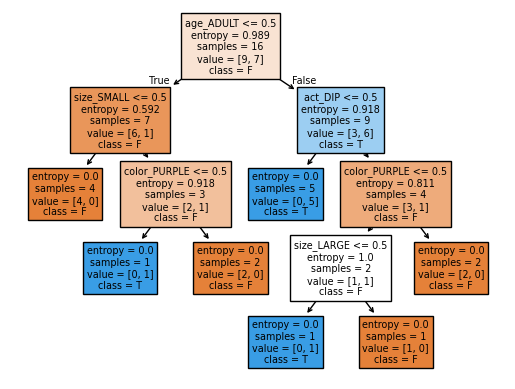

In [12]:
#This line plots the tree using the import from SKLearn through the 'plot_tree()' function.
#clf contains the trained decision tree, thus the function's main argument.
#The 'feature_names' parameter takes in the numerically converted attributes again and the 'class_names' takes in the target variable.
#Both of the parameters above are for naming the features in the tree (feature_names) and the values of the leaf nodes according to the target (class_names).
tree.plot_tree(clf, feature_names=X_encoded.columns, class_names=clf.classes_, filled=True)

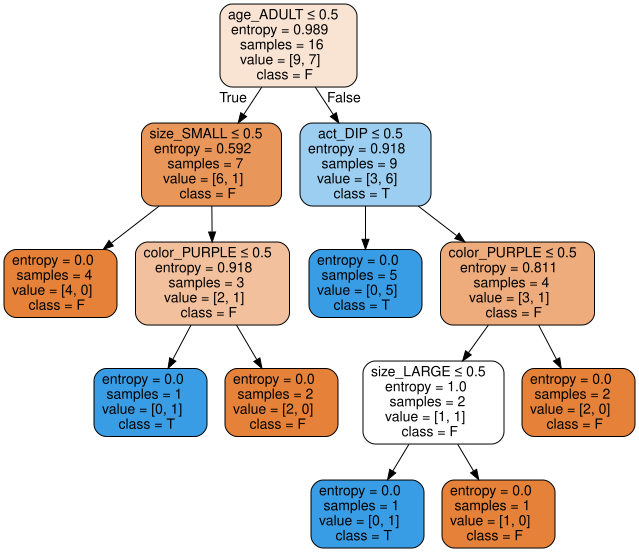

In [13]:
#Similar to the tree above, this line of code utilizes graphvis for a better tree visualization.
#However, this converts the clf decision tree into the DOT language.
#DOT Language is the abstract grammar designed for Graphviz, catering nodes, edges, graphs, etc (Graphviz, 2024).
#This line of code also takes in the feature_names and class_names for the node naming of the tree model.
#'filled' and 'rounded' parameter are mainly for readability.
dot_data = export_graphviz(clf, out_file=None,
                           feature_names=X_encoded.columns,
                           class_names=clf.classes_,
                           filled=True, rounded=True,
                           special_characters=True)

#This takes the DOT-language-converted tree to create a source object of Graphviz.
#'Source()' is a contructor that helps parse the DOT string to be rendered to a visual graph.
graph = graphviz.Source(dot_data)

#This displays the Graphviz graph that was setup earlier.
#This tree visualization is bigger, more readable, and clearer compared to the 'plot_tree()' function.
graph

# Examine Leaf Information
- - -

In [14]:
#This is the function that retrieves the leaf information of a tree.
#This will travers the internal structure of the trained tree to get the data from the leaf nodes.
def get_leaf_info(clf):
    #This accesses the tree object from the trained 'clf' which hols the representation of the tree's stucture and information.
    #This assignment provides the raw data needed to check the components of the tree and retrieve its data.
    tree = clf.tree_
    #This initializes an empty array named 'leaf_data'.
    #This will store values extracted and be returned later as a dataframe for output.
    leaf_data = []
    #This is a loop statement that goes through all the nodes of the tree.
    #'node_count' gives the total number of nodes in the tree to give the number of iterations.
    for node in range(tree.node_count):
        #This if-statement is to check if the current node is a leaf node.
        #This checks if there are no instances of a left or right child of the current node with the 'TREE_LEAF'.
        #If this is true, then the current node is a leaf and proceeds to retrieve node information.
        if (tree.children_left[node] == _tree.TREE_LEAF and 
            tree.children_right[node] == _tree.TREE_LEAF):
            #This line gets the actual class counts for each leaf
            #This is done by multiplying the weighted class probability with the total number of samples in the node.
            value = tree.value[node][0] * tree.n_node_samples[node]
            #This round the calculated value earler to the nearest integer and casts them as an integer type.
            #This is needed for cleaner class counts rather than float-points.
            value = np.round(value).astype(int)
            #This retrieves the total number of samples that had reached the specific leaf node.
            #'n_node_samples[]' is used to provide the count and is stored in the 'samples' variable.
            samples = tree.n_node_samples[node]
            #This retrieves the impurity measure of the leaf node.
            #Since entropy was used as the criterion when building the tree, that is the retreived impurity value.
            entropy = tree.impurity[node]
            #This determines the predicted class for the leaf node.
            #The function 'argmax()' finds the index of the class with the highest count among the value then gets the values of the target variable with 'classes_'.
            predicted_class = clf.classes_[value.argmax()]
            #This creates a 'class_dist' (class distribution) dictionary to show the distribution of samples across the values of the target feature.
            #This pairs each class label ('clf.classes_') with the corresponding count (value) to get the number of samples in each class in this leaf.
            class_dist = {label: count for label, count in zip(clf.classes_, value)}
            #This appends the gathered data in the 'leaf_data' dictionary initialized earlier.
            #Both the labels and its values are appended per leaf node in this loop.
            leaf_data.append({
                "Node": node,
                "Predicted Class": predicted_class,
                "Samples": samples,
                "Class Distribution": class_dist,
                "Entropy": round(entropy, 3)
            })
            
    #This returns the dictionary 'leaf_data' and converts it as a dataframe to be displayed for later.
    #The dataframe now contains the data of the leaves of the tree.
    return pd.DataFrame(leaf_data)

In [15]:
#This executes the 'get_leaf_info()' function and stores it inside the 'df' dataframe.
#This line uses the 'clf' which was the tree built and displayed earlier to examine its leaves.
df = get_leaf_info(clf)
#This line is just for readability and proper visualization labeling.
#This uses a markdown cell to display the Leaf Information title.
display(Markdown("### Leaf Information"))
#This line displays the dataframe 'df' that contains the Leaf Information Table.
#The display would describe and help examine specific leaf information better than the graph.
display(df)

#### Leaf Information

,Node,Predicted Class,Samples,Class Distribution,Entropy
0,2,F,4,"{'F': 4, 'T': 0}",0.0
1,4,T,1,"{'F': 0, 'T': 1}",0.0
2,5,F,2,"{'F': 2, 'T': 0}",0.0
3,7,T,5,"{'F': 0, 'T': 5}",0.0
4,10,T,1,"{'F': 0, 'T': 1}",0.0
5,11,F,1,"{'F': 1, 'T': 0}",0.0
6,12,F,2,"{'F': 2, 'T': 0}",0.0


## Examining Leaf Information Table
- - -

* The table above reveals that there are seven (7) leaf nodes in the decision tree.
  
* The node column lists the node IDs of the leaves, which was given according to a pre-order traversal.

**On Leaf Purity**

* All values under the Entropy column are zero which means that all seven leaves are **pure**.

* Samples under each leaf also have **ONLY ONE** class distribution, which explains the 0.0 entropy for all leaves.

* All leaves also belowng to its predicted class.

## Examining Leaf Paths
- - -

* **Node 3 Path:**
    > ```
    >age_ADULT ≤ 0.5 === True
    >    color_PURPLE ≤ 0.5 ===  True
    >        size_SMALL ≤ 0.5 === True
    >```
     
    > This leaf contains all where the balloon is for a **child**, is **yellow**, and is **large** in size.
    > 
    > With these characteristics, the balloon is **NOT** inflated.
    >
    > There are **2** samples of these in the dataset.

* **Node 4 Path:**
    > ```
    >age_ADULT ≤ 0.5 === True
    >    color_PURPLE ≤ 0.5 ===  True
    >        size_SMALL ≤ 0.5 === False
    >```
     
    > This leaf contains all where the balloon is for a **child**, is **yellow**, and is **small** in size.
    >     
    > With these characteristics, the balloon **IS INFLATED**.
    >
    > > There is **1** sample of this in the dataset.


* **Node 5 Path:**
    > ```
    >age_ADULT ≤ 0.5 === True
    >    color_PURPLE ≤ 0.5 ===  False
    >```
     
    > This leaf contains all where the balloon is for a **child** and is **yellow**.
    >  
    > With these characteristics, the balloon is **NOT** Inflated.
    >
    > > There are **4** samples of these in the dataset.


* **Node 7 Path:**
    > ```
    >age_ADULT ≤ 0.5 === False
    >    act_DIP ≤ 0.5 ===  True
    >```
     
    > This leaf contains all where the balloon is for an **adult** and **stretches**.
    >
    > With these characteristics, the balloon **IS INFLATED**.
    >
    > > There are **5** samples of these in the dataset.

* **Node 9 Path:**
    > ```
    >age_ADULT ≤ 0.5 === False
    >    act_DIP ≤ 0.5 ===  False
    >        size_SMALL ≤ 0.5 === True
    >```
     
    > This leaf contains all where the balloon is for an **adult**, **dips**, and is **large** in size.
    >
    > With these characteristics, the balloon is **NOT** Inflated.
    >
    > There are **2** samples of these in the dataset.

* **Node 11 Path:**
    > ```
    >age_ADULT ≤ 0.5 === False
    >    act_DIP ≤ 0.5 ===  False
    >        size_SMALL ≤ 0.5 === False
    >            color_YELLOW ≤ 0.5 === True
    >```
     
    > This leaf contains all where the balloon is for an **adult**, **dips**, and is **small** in size, and is **purple**.
    >
    > With these characteristics, the balloon is **NOT** Inflated.
    >
    > There is **1** sample of this in the dataset.

* **Node 12 Path:**
    > ```
    >age_ADULT ≤ 0.5 === False
    >    act_DIP ≤ 0.5 ===  False
    >        size_SMALL ≤ 0.5 === False
    >            color_YELLOW ≤ 0.5 === False
    >```
     
    > This leaf contains all where the balloon is for an **adult**, **dips**, and is **small** in size, and is **yellow**.
    >
    > With these characteristics, the balloon **IS INFLATED**.
    >
    > There is **1** sample of this in the dataset.


    

# Experiment
- - -

## **Tree with a Maximum Depth of 1**
 - - -

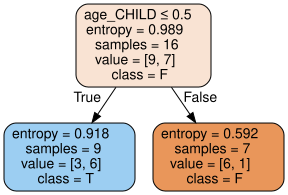

#### Leaf Information

,Node,Predicted Class,Samples,Class Distribution,Entropy
0,1,T,9,"{'F': 3, 'T': 6}",0.918
1,2,F,7,"{'F': 6, 'T': 1}",0.592


## **Tree with a Maximum Depth of 2**
 - - -

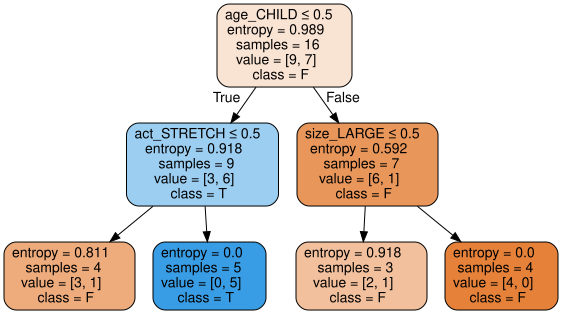

#### Leaf Information

,Node,Predicted Class,Samples,Class Distribution,Entropy
0,2,F,4,"{'F': 3, 'T': 1}",0.811
1,3,T,5,"{'F': 0, 'T': 5}",0.000
2,5,F,3,"{'F': 2, 'T': 1}",0.918
3,6,F,4,"{'F': 4, 'T': 0}",0.000


## **Tree with a Maximum Depth of 3**
 - - -

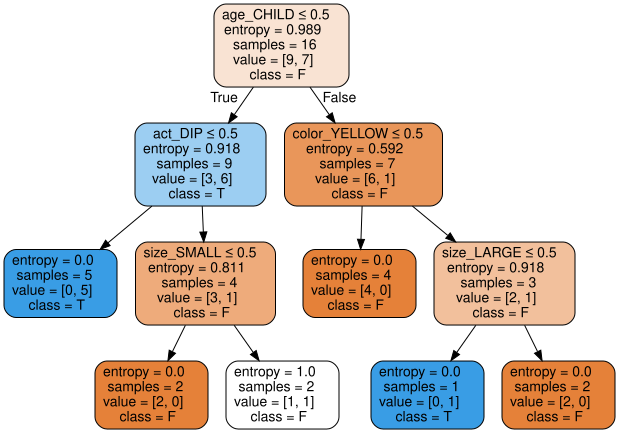

#### Leaf Information

,Node,Predicted Class,Samples,Class Distribution,Entropy
0,2,T,5,"{'F': 0, 'T': 5}",0.0
1,4,F,2,"{'F': 2, 'T': 0}",0.0
2,5,F,2,"{'F': 1, 'T': 1}",1.0
3,7,F,4,"{'F': 4, 'T': 0}",0.0
4,9,T,1,"{'F': 0, 'T': 1}",0.0
5,10,F,2,"{'F': 2, 'T': 0}",0.0


## **Tree with a Maximum Depth of None**
 - - -

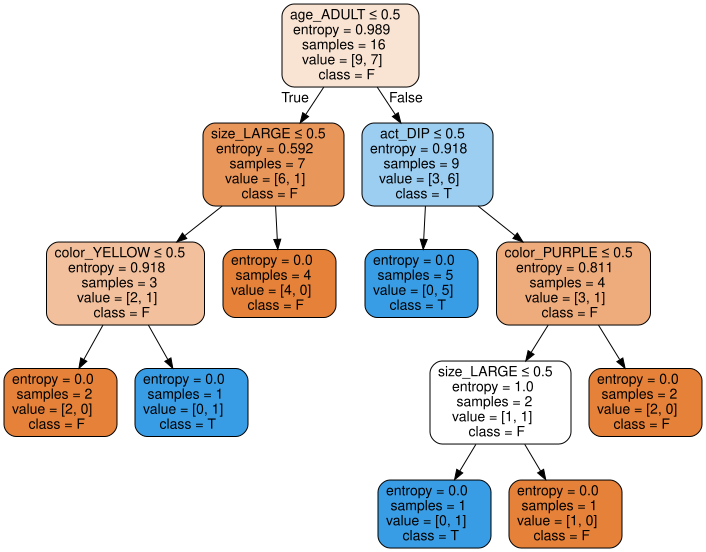

#### Leaf Information

,Node,Predicted Class,Samples,Class Distribution,Entropy
0,3,F,2,"{'F': 2, 'T': 0}",0.0
1,4,T,1,"{'F': 0, 'T': 1}",0.0
2,5,F,4,"{'F': 4, 'T': 0}",0.0
3,7,T,5,"{'F': 0, 'T': 5}",0.0
4,10,T,1,"{'F': 0, 'T': 1}",0.0
5,11,F,1,"{'F': 1, 'T': 0}",0.0
6,12,F,2,"{'F': 2, 'T': 0}",0.0


In [16]:
#As per the activity's instructions the maximum depth would go through from None up to 3.
#This is a loop to iterate maximum depths while displaying the tree and its leaf information.
for depth in [1, 2, 3, None]:

    #Inside this loop, a decision tree is initialized with the entropy criterian.
    #This also uses the depth array declared above to go through different maximum tree depths for each iteration.
    clf = DecisionTreeClassifier(criterion="entropy", max_depth=depth)

    #This line trains and fits the previously used 'X_encoded' and 'y' variables, which are the numerical data of the features and the target feature.
    #The 'fit()' method helps learn the decision rules based on the entered 'max_depth' parameters.
    clf.fit(X_encoded, y)
    
    #This code generates the Graphvis representation of the current tree that has been recently trained based on the current iteration.
    #The function 'export_graphviz()' takes the 'clf' as its main argument to process and display.
    #Parameters such as 'feature_names' and 'class_names' help define the names of the tree nodes, with a bit of a casting to a string ('.astype(str)') for better output.
    #Other parameters such as 'out_file=None' ensures that the output is a string, 'filled=True', 'rounded=True', and 'special_character=True' aid in the readability of the graph.
    dot_data = export_graphviz(
        clf,
        out_file=None,
        feature_names=X_encoded.columns,
        class_names=clf.classes_.astype(str),
        filled=True, rounded=True,
        special_characters=True
    )

    #This creates a 'graphviz.Source' object from the 'dot_data' generated above.
    #This prepares the rendering of the Graphviz graph defintion.
    graph = graphviz.Source(dot_data)
    #This line adds a markdown cell describing the maximum depth of the tree for visualization titles.
    #Special characters include '#' for heading, '**' for emphasis, and '- - -' for a horizontal rule. 
    display(Markdown(f"## **Tree with a Maximum Depth of {depth}**\n - - -"))
    #This code is for the inline rendering of the output.
    #This guarantees that the tree visualizations are displayed in the notebook despite being inside the loop.
    display(graph) 

    #This executes the 'get_leaf_info()' function and stores it inside the 'df' dataframe.
    #This line uses the 'clf' which was the tree built and displayed earlier to examine its leaves.
    df = get_leaf_info(clf)
    #This line is just for readability and proper visualization labeling.
    #This uses a markdown cell to display the Leaf Information title.
    display(Markdown("#### Leaf Information"))
    #This line displays the dataframe 'df' that contains the Leaf Information Table.
    #The display would describe and help examine specific leaf information better than the graph.
    display(df)

### Discussion
- - -
#### Tree with a Maximum Depth of One (1)

* Only a single split is observed
  > Split only on attribute 'age'.
* There are a total of 3 nodes.

* There are a total of 2 leaf nodes.

#### Tree with a Maximum Depth of Two (2)

* Three (3) splits are observed
  > Split on attribute 'age' (Root).
  > 
  > Split on attribute 'act' (Branch 1).
  > 
  > Split on attribute 'size' (Branch 2).
* There are a total of 7 nodes.

* There are a total of 4 leaf nodes.

#### Tree with a Maximum Depth of Three (3)

* Five (5) splits are observed
  > Split on attribute 'age' (Root).
  > 
  > Split on attribute 'act' (Branch 1).
  > 
  > Split on attribute 'color' (Branch 2).
  >
  > Split on attribute 'size' (Branch 1.1).
  >
  > Split on attribute 'size' (Branch 2.1).
* There are a total of 11 nodes.

* There are a total of 6 leaf nodes.

#### Tree with a Maximum Depth of None 

* Six (6) splits are observed
  > Split on attribute 'age' (Root).
  > 
  > Split on attribute 'size' (Branch 1).
  >
  > Split on attribute 'color' (Branch 1.1).
  >
  > Split on attribute 'color' (Branch 1.1.1).
  > 
  > Split on attribute 'act' (Branch 2).
  >
  > Split on attribute 'color' (Branch 2.1).
  >
  > Split on attribute 'size' (Branch 2.1.1).
* There are a total of 13 nodes.

* There are a total of 7 leaf nodes.

### Insights
- - -

* Tree with a maximum depth of one (1) has a small tree but has impure leaf nodes and uneven/non-uniform class distribution.
  > Both entropies of the leaf nodes have high values:
  > * 0.918 (Left)
  > * 0.592 (Right)

* Tree with a maximum depth of two (2) still has impure leaf nodes and uneven/non-uniform class distributions, but less compared the ```max_depth = 1```.
  > Two (2) leaf nodes have an entropy of 0.0
  > 
  > While the other two (2) nodes still have high entropy values:
  > * 0.811
  > * 0.918

* Tree with a maximum depth of three (3) has one impure leaf node, with the rest having purity and equal/uniform class distributions.
  > Five (5) leaf nodes have an entropy of 0.0
  > 
  > While the only one (1) nodes still have high entropy values:
  > * 1.0

* Tree with a maximum depth of none has puure leaf nodes and equal/uniform class distributions.
  > All seven (7) leaf nodes have an entropy of 0.0
  > 

* A small maximum depth causes the tree splitting to be limited.

* A limited tree causes the leaf nodes to be impure and a uneven/non-uniform class distributions.

* In this experiment, more splitting led to pure leaf nodes.
  > This may be limited to the right attribute for splitting to achieve purity.
  >
  > An entropy of zero must be the limit to stop the splitting and avoid overfitting.

# **Post-Lab Questions**
- - -


##### 1. Based on the "Initial Splitting Criteria" table, which attribute was chosen as the root node of the decision tree? Why?

Attribute 'Age' is the root node of the decision tree as this was the one with the highest information gain among other attributes for the first split.

##### 2. Consider one branch from the root node. What attribute would be chosen for the next split in that particular branch, and why?

For the left side from the root node, attribute 'Size' would be chosen as this was the attribute with the highest information gain among the remaining unsued attributes for splitting.

##### 3. How does the concept of entropy relate to the purity of a node in a decision tree?

Entropy means the randomness of a data. Once entropy becomes or reaches zero (0), a node containing a subset data of samples becomes pure, sharing one unique value from the target feature. This pure node also becomes a leaf node.

##### 4. Explain in your own words why information gain is used to select the best splitting attribute.

Information gain takes is the reduced entropy when an attribute is used to split, therefore reducing the data's randomness or uncertainty. A higher information gain means that a higher quantity of entropy was reduced, therfore making the data purer.     

##### 5. If you set MAX_TREE_DEPTH = 1, how would the resulting tree look, and what would be the characteristics of its leaf nodes? (Refer to your experimental run if you did this).

The resulting tree would only have three (3) total nodes: 1 root node and 2 children. The leaf nodes of this tree would be impure, having high entropy values. 

In my experimental runs, the left child of the root (node id: 2) has an entropy value of 0.918, while the right child (node id: 3) has an entropy value of 0.592. Furthermore, the distribution among classes is not even and uniform, with [F: 3,T: 6] for the left leaf node and [F: 6,T: 1] for the right leaf node. Its target classes have been determined through getting the most frequent value occuring in the split.

##### 6. What attribute is used in the first split? (Highlight this on your submission.)_

> ### Attribute 'Age' is used for the first split.

##### 7. What attribute is on the last split for a full tree? (Highlight this on your submission.)

> ### Attribute 'Size' is used on the last split for the full tree


# **Bibliograhy**
- - -

 GeeksforGeeks. (2024, July 2). Implementing Decision Tree Classifiers with ScikitLearn. GeeksforGeeks. 

 Graphviz. (2021). Graphviz - Graph Visualization Software. 

 Graphviz. (2024). DOT Language. Graphviz. 

 Numpy. (2024). NumPy. Numpy.org. 

 Pandas. (2018). Python Data Analysis Library. 

 Pandas. (2024). pandas.DataFrame.mode — pandas 1.4.1 documentation. Pandas.pydata.org.

 Scikit Learn. (2019). sklearn.tree.DecisionTreeClassifier — scikit-learn 0.22.1 documentation. Scikit-Learn.org.

 Scikit Learn. (2025). 1.10. Decision Trees — scikit-learn 0.22 documentation. Scikit-Learn.org.

 The IPython Development Team. (2025). ipython: IPython: Productive Interactive Computing. PyPI. 